# Week 5 Part A ? Rebuild nine charts, then take them apart

This notebook reproduces each published claim from its recipe, records the supplied self-checks, identifies the exact visual or analytical mechanism that misleads, and plots an honest redesign. All data are synthetic Week 5 data.

**Conventions used throughout:** area channels use area (not radius); every size channel has a three-value legend; quantitative amount uses sequential lightness rather than rainbow hue; rates state their denominator; class breaks are printed; geographic measurements use an equal-area approximation; and every map names its units/source/year.


In [1]:
from pathlib import Path
import json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.cm import ScalarMappable
from scipy import stats

try:
    import seaborn as sns
    sns.set_theme(style='whitegrid', context='notebook')
except ImportError:
    plt.style.use('seaborn-v0_8-whitegrid')

BASE = Path.cwd()
if not (BASE / 'health_indicators.csv').exists() and (BASE / 'Week5').exists():
    BASE = BASE / 'Week5'
DATA_YEAR = 'synthetic Week 5 data (year not supplied)'
health = pd.read_csv(BASE / 'health_indicators.csv')
district = pd.read_csv(BASE / 'district_health.csv')
flat = pd.read_csv(BASE / 'case05_flat_rates.csv')
small = pd.read_csv(BASE / 'smallarea_cases.csv')
profiles = pd.read_csv(BASE / 'region_profiles.csv')
with open(BASE / 'districts.geojson', encoding='utf-8') as f:
    geo = json.load(f)
features = geo['features']

print('Data directory:', BASE)
print('Health rows:', len(health), '| District rows:', len(district), '| Geo features:', len(features))


Data directory: d:\University\ML Lab\Week5
Health rows: 60 | District rows: 24 | Geo features: 24


In [2]:
def minmax(s):
    return (s - s.min()) / (s.max() - s.min())

def robust_scale(s, low=0.05, high=0.95):
    a, b = s.quantile([low, high])
    return ((s.clip(a, b) - a) / (b - a)).clip(0, 1)

def geo_records():
    return {f['properties']['code']: f['geometry']['coordinates'][0] for f in features}

def project_ring(ring):
    # Local equal-area approximation: x=longitude*cos(mean latitude), y=latitude.
    lat0 = np.mean([p[1] for p in ring])
    return np.array([(p[0] * math.cos(math.radians(lat0)), p[1]) for p in ring])

def draw_map(values, title, cmap='Blues', breaks=None, value_label='', ax=None):
    ax = ax or plt.subplots(figsize=(10, 7))[1]
    codes = geo_records()
    vals = pd.Series(values, dtype=float)
    if breaks is None:
        norm = Normalize(vals.min(), vals.max())
        colors = {k: plt.get_cmap(cmap)(norm(v)) for k, v in vals.items()}
    else:
        norm = BoundaryNorm(breaks, ncolors=plt.get_cmap(cmap).N, clip=True)
        colors = {k: plt.get_cmap(cmap)(norm(v)) for k, v in vals.items()}
    for code, ring in codes.items():
        xy = project_ring(ring)
        ax.fill(xy[:,0], xy[:,1], color=colors.get(code, 'lightgrey'), ec='white', lw=.6)
    sm = ScalarMappable(norm=norm, cmap=cmap); sm.set_array([])
    cb = plt.colorbar(sm, ax=ax, shrink=.75, pad=.02); cb.set_label(value_label)
    ax.set_title(title); ax.set_xlabel('Equal-area x (projected degrees)'); ax.set_ylabel('Equal-area y (projected degrees)')
    return ax

def natural_breaks(s, k=5):
    x = np.sort(np.asarray(s, dtype=float))
    cuts = [x.min()]
    groups = np.array_split(x, k)
    for g in groups[:-1]: cuts.append(g.max())
    cuts.append(x.max())
    return np.unique(cuts)

def class_labels(values, breaks):
    return pd.cut(values, bins=breaks, include_lowest=True, duplicates='drop')

def parallel(df, cols, title, scaler=minmax, ax=None):
    ax = ax or plt.subplots(figsize=(12, 5))[1]
    z = pd.DataFrame({c: scaler(df[c]) for c in cols})
    x = np.arange(len(cols))
    for row in z.itertuples(index=False): ax.plot(x, row, color='#31688e', alpha=.16, lw=.8)
    ax.set_xticks(x, cols, rotation=25, ha='right'); ax.set_ylim(0,1); ax.set_ylabel('Scaled value (0?1)'); ax.set_title(title)
    return z, ax

def add_size_legend(ax, values, labels, color='#31688e'):
    handles = [plt.scatter([], [], s=float(v), color=color, alpha=.55, edgecolor='black') for v in values]
    ax.legend(handles, labels, title='Population (million people)\nmarker area', scatterpoints=1, loc='best')


## 1. Population and healthcare access

**Invited conclusion:** population and healthcare access are unrelated because large countries appear across the horizontal range.

**First objection and why it does not hold:** a distorted size channel could be blamed, but the x/y coordinates and log x-axis are exactly the recipe; the supplied data still contain the stated 589-fold population range, so the claim is being invited by the size encoding rather than by a manipulated axis.

**Mechanism:** `s=pop_m**2` makes marker **area** proportional to population squared. The largest area is 589? = 347,? times the smallest in the recipe, not 589 times; this overwhelms the display and makes nine sub-2M countries smaller than a point.


Self-check marks: 60 | area ratio max/min: 346921.0 | expected population ratio: 589 | sub-2M: 9


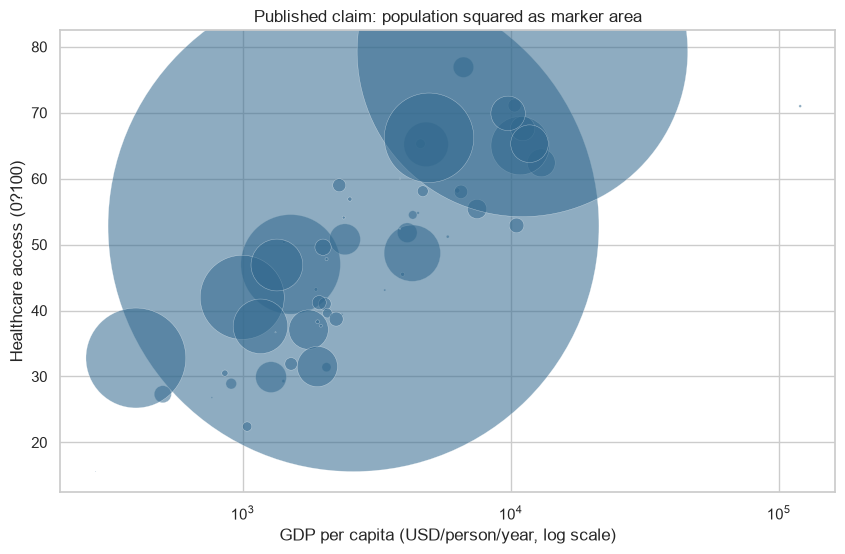

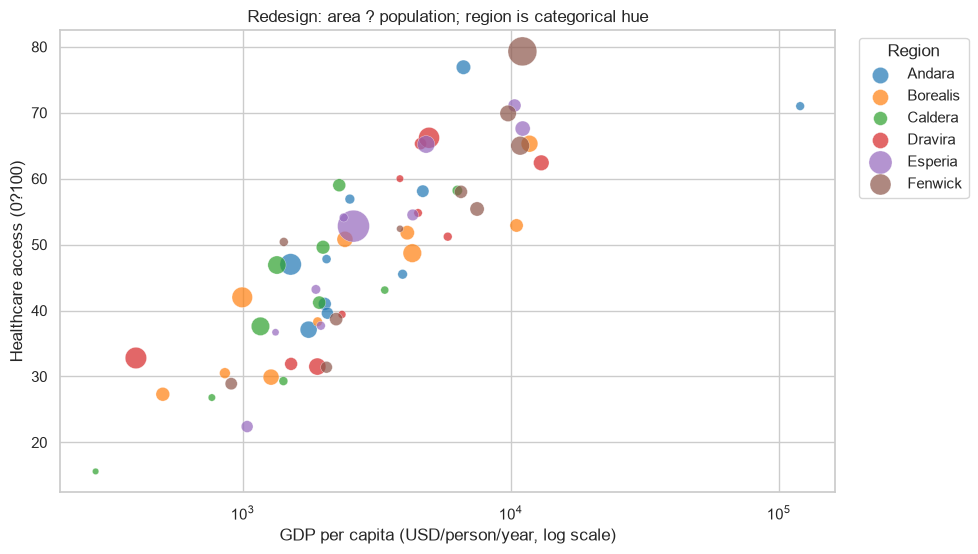

In [3]:
fig, ax = plt.subplots(figsize=(10,6))
ax.scatter(health.gdp_pc, health.healthcare_access, s=health.pop_m**2, alpha=.55, color='#31688e', edgecolor='white', linewidth=.3)
ax.set_xscale('log'); ax.set(xlabel='GDP per capita (USD/person/year, log scale)', ylabel='Healthcare access (0?100)', title='Published claim: population squared as marker area')
marks = health.pop_m**2
print('Self-check marks:', len(health), '| area ratio max/min:', round(marks.max()/marks.min(), 0), '| expected population ratio:', round(health.pop_m.max()/health.pop_m.min()), '| sub-2M:', int((health.pop_m < 2).sum()))
plt.show()

fig, ax = plt.subplots(figsize=(10,6))
colors = plt.get_cmap('tab10')
for i, (region, g) in enumerate(health.groupby('region')):
    ax.scatter(g.gdp_pc, g.healthcare_access, s=np.sqrt(g.pop_m)*28, color=colors(i), alpha=.7, label=region, edgecolor='white', linewidth=.3)
ax.set_xscale('log'); ax.set(xlabel='GDP per capita (USD/person/year, log scale)', ylabel='Healthcare access (0?100)', title='Redesign: area ? population; region is categorical hue')
add_size_legend(ax, np.sqrt(np.array([1, 25, 100]))*28, ['1M', '25M', '100M'])
ax.legend(title='Region', bbox_to_anchor=(1.02,1), loc='upper left'); plt.show()


## 2. Outbreak concentration near the capital

**Invited conclusion:** the outbreak is concentrated in D17, D13, and D09, the three districts with the largest counts.

**First objection and why it does not hold:** the join might have silently dropped districts, but the explicit join check below verifies all 24 codes matched.

**Mechanism:** raw `cases` is a count while populations differ substantially; the legend therefore encodes opportunity/exposure as well as incidence. The honest decision is to normalize by population and state the denominator.


Join check: 24 matched; unmatched table: [] | unmatched geometry: []
Published natural breaks (cases): [ 186.  303.  710.  989. 1770. 5588.]
Top three by count:
 code district  cases  population
 D17  Qilabad   5588    10966000
 D13 Mehrabad   4048     6327000
 D09 Ilyaspur   3437     6886000


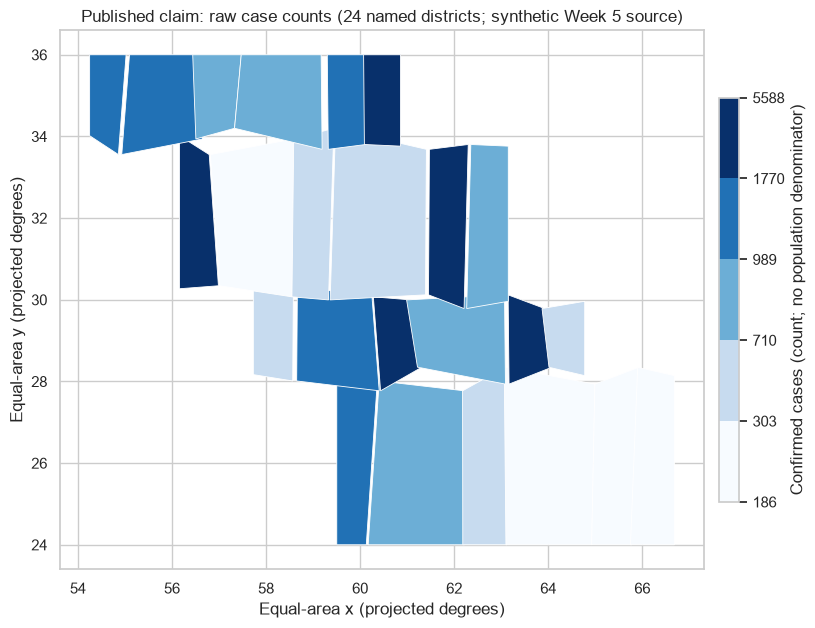

Rate natural breaks (cases per 100,000): [30.44 43.27 49.79 54.4  63.98 76.47]
code   district      rate  cases  population
 D19 Sibbi East 76.467331   1381     1806000
 D20     Tarmak 74.179104    994     1340000
 D21     Ushkan 68.825162    744     1081000


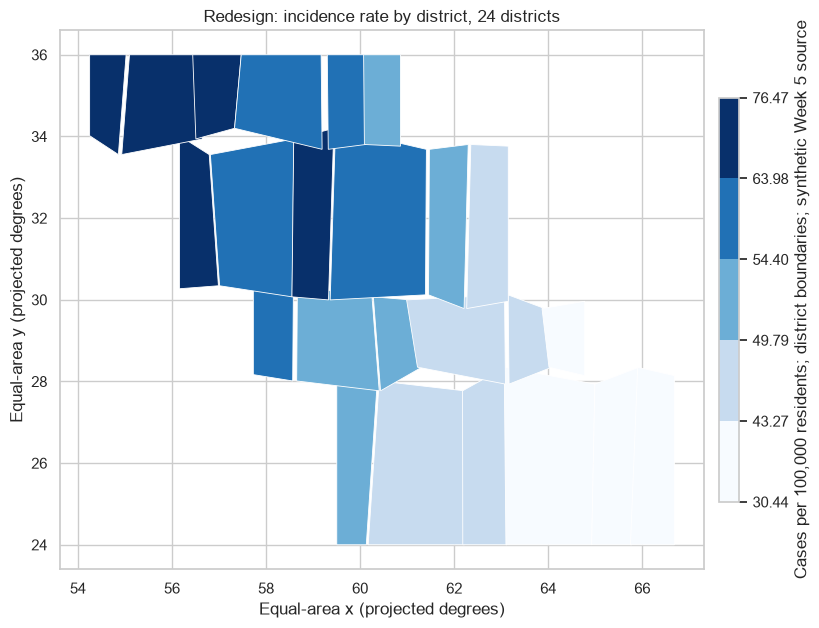

In [4]:
geo_codes = set(geo_records())
matched = set(district.code) & geo_codes
print('Join check:', len(matched), 'matched; unmatched table:', sorted(set(district.code)-geo_codes), '| unmatched geometry:', sorted(geo_codes-set(district.code)))
count_breaks = natural_breaks(district.cases, 5)
print('Published natural breaks (cases):', np.round(count_breaks, 1))
top_count = district.nlargest(3, 'cases')[['code','district','cases','population']]
print('Top three by count:\n', top_count.to_string(index=False))
draw_map(district.set_index('code').cases, 'Published claim: raw case counts (24 named districts; synthetic Week 5 source)', breaks=count_breaks, value_label='Confirmed cases (count; no population denominator)'); plt.show()

district = district.assign(rate=district.cases/district.population*1e5)
rate_breaks = natural_breaks(district.rate, 5)
print('Rate natural breaks (cases per 100,000):', np.round(rate_breaks, 2))
print(district.nlargest(3, 'rate')[['code','district','rate','cases','population']].to_string(index=False))
draw_map(district.set_index('code').rate, 'Redesign: incidence rate by district, 24 districts', breaks=rate_breaks, value_label='Cases per 100,000 residents; district boundaries; synthetic Week 5 source'); plt.show()


## 3. GDP per capita barely varies

**Invited conclusion:** GDP per capita is almost flat, so it barely varies.

**First objection and why it does not hold:** the scale is not a plotting typo; min?max scaling genuinely anchors every value to the single extreme maximum.

**Mechanism:** min?max is sensitive to the 9.2? gap between the largest and second-largest GDP values. That decision compresses 58 of 60 observations below 0.10 and makes the median 0.017.


GDP below 0.10: 58 / 60 | median: 0.017


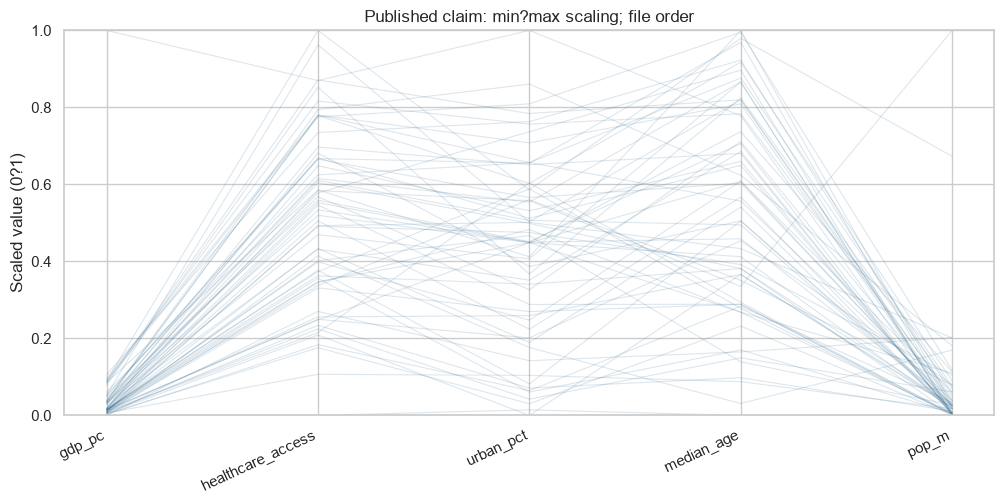

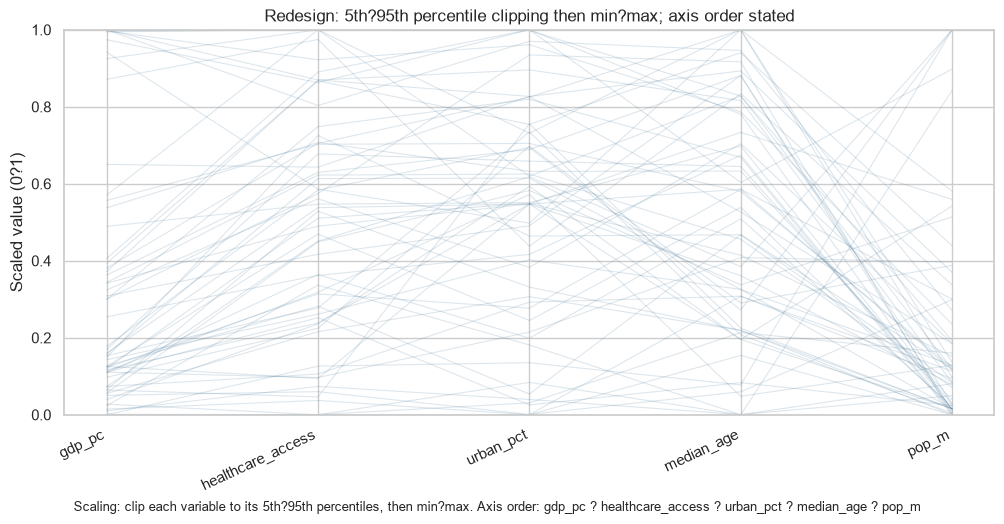

In [5]:
num_cols = ['gdp_pc','healthcare_access','urban_pct','median_age','pop_m']
z_min, ax = parallel(health, num_cols, 'Published claim: min?max scaling; file order', minmax)
print('GDP below 0.10:', int((z_min.gdp_pc < .10).sum()), '/ 60 | median:', round(z_min.gdp_pc.median(), 3))
plt.show()
z_robust, ax = parallel(health, num_cols, 'Redesign: 5th?95th percentile clipping then min?max; axis order stated', robust_scale)
ax.text(.01, -.25, 'Scaling: clip each variable to its 5th?95th percentiles, then min?max. Axis order: ' + ' ? '.join(num_cols), transform=ax.transAxes, fontsize=9)
plt.show()


## 4. Healthcare access and case rate are unrelated

**Invited conclusion:** there is no crossing pattern between healthcare access and incidence.

**First objection and why it does not hold:** the lines are the same observations and the arithmetic is unchanged; the apparent absence is caused by reading non-adjacent axes as if they were adjacent.

**Mechanism:** file order places `urban_pct` and `median_age` between `healthcare_access` and `cases_per_100k`; they are three axes apart. Axis order is the lying decision.


Axes: ['gdp_pc', 'healthcare_access', 'urban_pct', 'median_age', 'cases_per_100k'] | healthcare_access index: 1 | cases_per_100k index: 4 | axes apart: 3


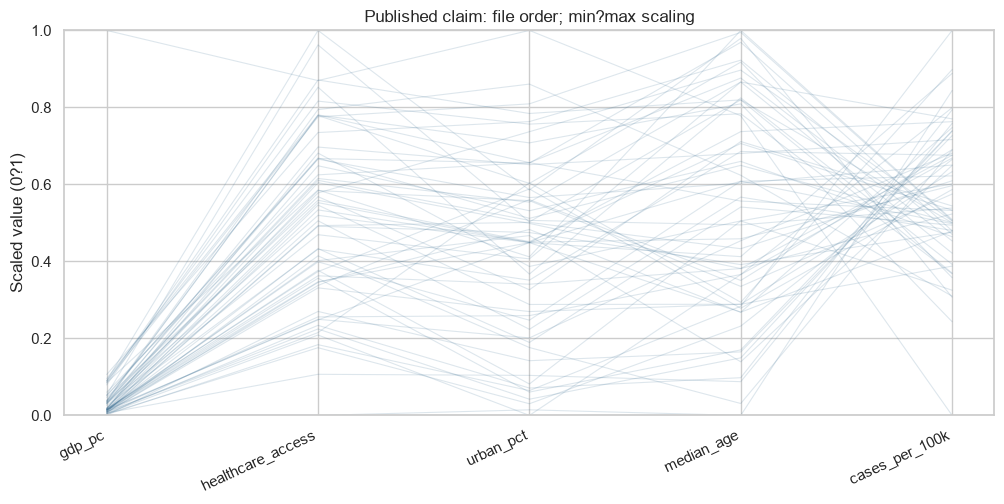

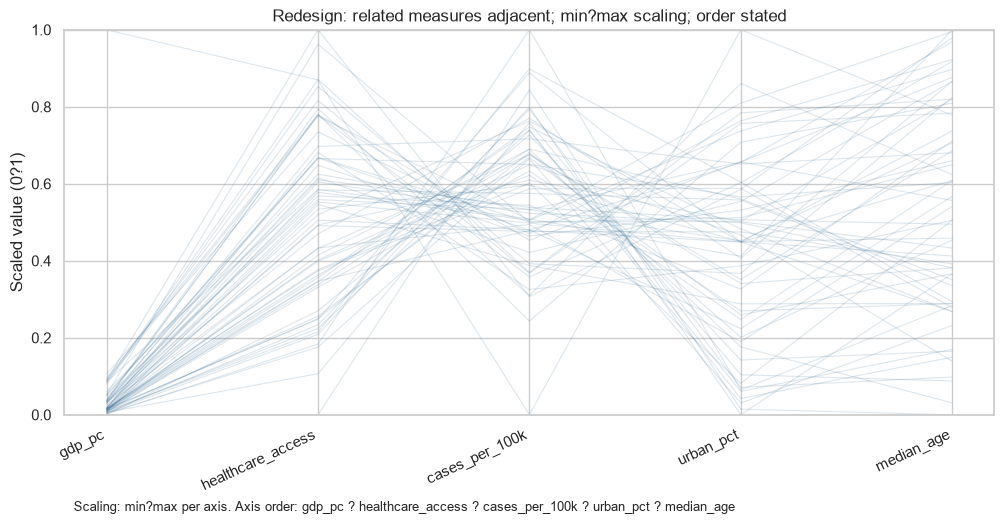

In [6]:
file_order = ['gdp_pc','healthcare_access','urban_pct','median_age','pop_m','cases_per_100k']
# The assignment describes five axes; use the five analysis variables and retain incidence in the explicit comparison order.
file_order = ['gdp_pc','healthcare_access','urban_pct','median_age','cases_per_100k']
z4, ax = parallel(health, file_order, 'Published claim: file order; min?max scaling', minmax)
print('Axes:', file_order, '| healthcare_access index:', file_order.index('healthcare_access'), '| cases_per_100k index:', file_order.index('cases_per_100k'), '| axes apart:', abs(file_order.index('healthcare_access')-file_order.index('cases_per_100k')))
plt.show()
redesign_order = ['gdp_pc','healthcare_access','cases_per_100k','urban_pct','median_age']
z4r, ax = parallel(health, redesign_order, 'Redesign: related measures adjacent; min?max scaling; order stated', minmax)
ax.text(.01, -.25, 'Scaling: min?max per axis. Axis order: ' + ' ? '.join(redesign_order), transform=ax.transAxes, fontsize=9); plt.show()


## 5. Five-level gradient in incidence

**Invited conclusion:** five map colours imply five meaningful incidence levels.

**First objection and why it does not hold:** quantiles do create five nonempty classes, but the rates themselves are nearly identical; the classification, not the data, creates the apparent gradient.

**Mechanism:** quantile classification forces equal-ish membership into five hues. The full rate range is only 31.07?33.40 per 100,000, a 7.2% spread of the mean.


Districts: 24 | rate range: 31.07 to 33.4 | spread/mean %: 7.2
Published quantile breaks: [31.07 31.49 32.07 32.51 32.94 33.4 ]


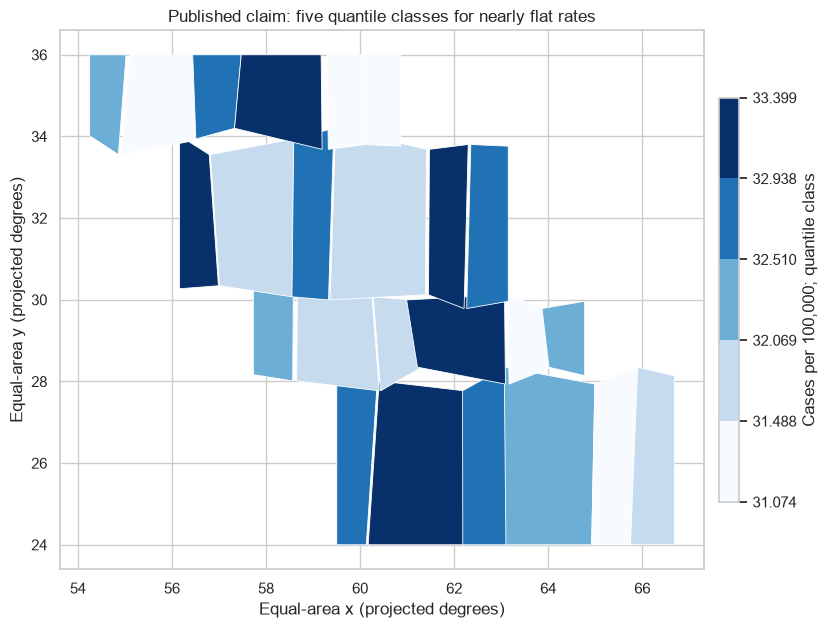

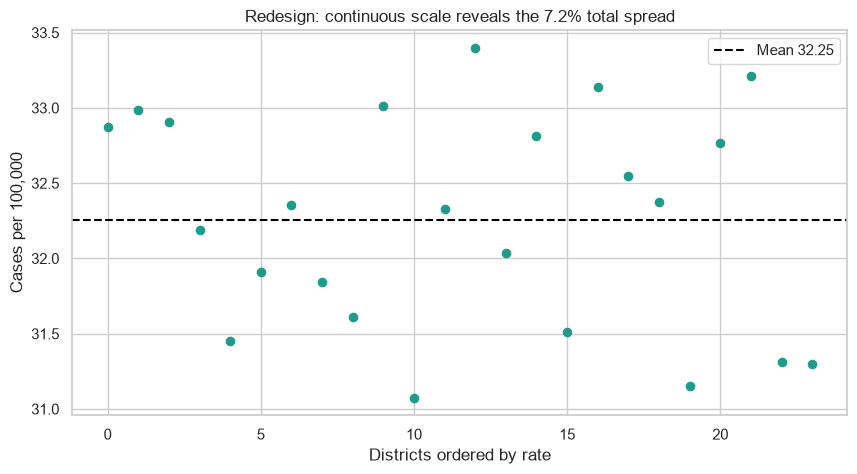

In [7]:
flat = flat.assign(rate=flat.cases/flat.population*1e5)
qbreaks = np.unique(flat.rate.quantile(np.linspace(0,1,6)).to_numpy())
print('Districts:', len(flat), '| rate range:', round(flat.rate.min(),2), 'to', round(flat.rate.max(),2), '| spread/mean %:', round((flat.rate.max()-flat.rate.min())/flat.rate.mean()*100,1))
print('Published quantile breaks:', np.round(qbreaks,2))
draw_map(flat.set_index('code').rate, 'Published claim: five quantile classes for nearly flat rates', cmap='Blues', breaks=qbreaks, value_label='Cases per 100,000; quantile class'); plt.show()
fig, ax = plt.subplots(figsize=(10,5)); ax.axhline(flat.rate.mean(), color='black', ls='--', label=f'Mean {flat.rate.mean():.2f}')
ax.scatter(flat.sort_values('rate').index, flat.sort_values('rate').rate, color=plt.get_cmap('viridis')(.55), s=35)
ax.set(xlabel='Districts ordered by rate', ylabel='Cases per 100,000', title='Redesign: continuous scale reveals the 7.2% total spread'); ax.legend(); plt.show()


## 6. U32 is a hotspot

**Invited conclusion:** U32 is running at nearly five times the national rate.

**First objection and why it does not hold:** U32 is not a data-entry error; its rate is exactly 9 cases in 22,000 people.

**Mechanism:** an unstable ratio from a small denominator and nine events is ranked beside large units as if precision were equal. The redesign shows Poisson uncertainty, so the high point is not treated as a stable hotspot.


Units: 40 | pooled rate: 8.72 | U32: 40.9 | ratio: 4.7 | U32 source: 9 cases in 22000 people
10 large-unit range: 5.5 to 12.0 | count: 10


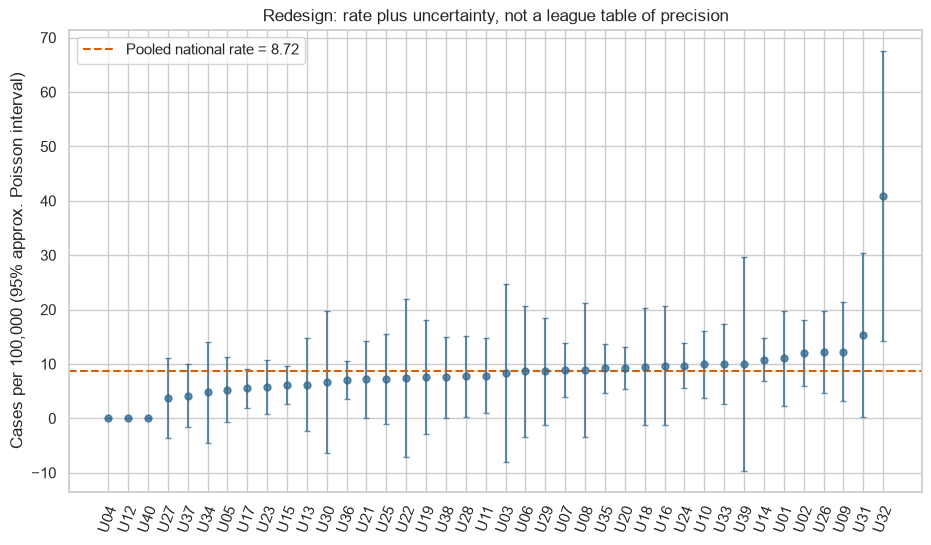

In [8]:
small = small.assign(rate=small.cases/small.population*1e5, se=np.sqrt(small.cases)/small.population*1e5)
pooled = small.cases.sum()/small.population.sum()*1e5
u32 = small.loc[small.unit.eq('U32')].iloc[0]
print('Units:', len(small), '| pooled rate:', round(pooled,2), '| U32:', round(u32.rate,1), '| ratio:', round(u32.rate/pooled,1), '| U32 source:', int(u32.cases), 'cases in', int(u32.population), 'people')
large = small[small.population > 100000]
print('10 large-unit range:', round(large.rate.min(),1), 'to', round(large.rate.max(),1), '| count:', len(large))
fig, ax = plt.subplots(figsize=(11,6)); order=small.sort_values('rate')
x=np.arange(len(order)); ax.errorbar(x, order.rate, yerr=1.96*order.se, fmt='o', ms=5, alpha=.75, color='#31688e', capsize=2)
ax.axhline(pooled, color='#d95f02', ls='--', label=f'Pooled national rate = {pooled:.2f}')
ax.set_xticks(x, order.unit, rotation=70); ax.set_ylabel('Cases per 100,000 (95% approx. Poisson interval)'); ax.set_title('Redesign: rate plus uncertainty, not a league table of precision'); ax.legend(); plt.show()


## 7. District income and case rate

**Invited conclusion:** income and case rate are only weakly related because Pearson r is ?0.308.

**First objection and why it does not hold:** the coefficient is reproducible across all 24 districts, so this is not a rounding or missing-row issue.

**Mechanism:** a single correlation compresses a spatially aggregated relationship into one number and does not show nonlinearity, influential districts, or zoning sensitivity.


Pearson r: -0.308 | p-value: 0.1426 | n: 24


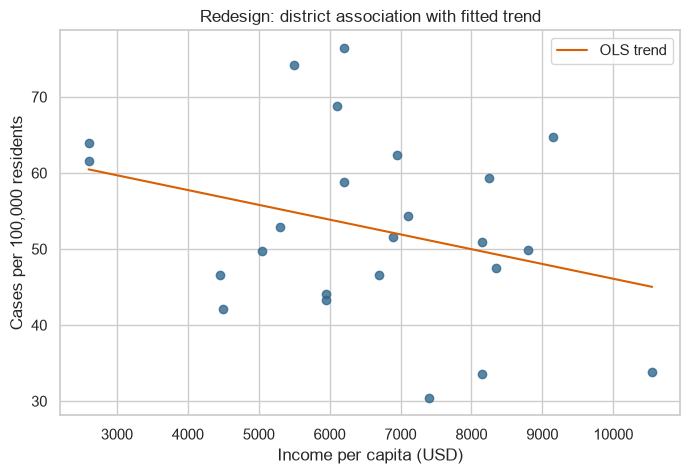

Interpretation: r describes linear association among these 24 districts; it does not establish causation.


In [9]:
r, p = stats.pearsonr(district.income_pc_usd, district.rate)
print('Pearson r:', round(r,3), '| p-value:', round(p,4), '| n:', len(district))
fig, ax = plt.subplots(figsize=(8,5)); ax.scatter(district.income_pc_usd, district.rate, color='#31688e', alpha=.8)
m,b = np.polyfit(district.income_pc_usd, district.rate, 1); xx=np.linspace(district.income_pc_usd.min(), district.income_pc_usd.max(),100)
ax.plot(xx, m*xx+b, color='#d95f02', label='OLS trend'); ax.set(xlabel='Income per capita (USD)', ylabel='Cases per 100,000 residents', title='Redesign: district association with fitted trend'); ax.legend(); plt.show()
print('Interpretation: r describes linear association among these 24 districts; it does not establish causation.')


## 8. Rural outbreak

**Invited conclusion:** the outbreak is rural because much of the map is dark.

**First objection and why it does not hold:** the dark area is not necessarily where most people live. The five most populous districts occupy little land but contain most of the population.

**Mechanism:** area is being used as a visual proxy for population. District land areas vary 5.7?, while population density varies 6?327 people/km?; a map-area impression cannot answer a population question.


Five most populous districts land share: 12.6 % | population share: 59.9 %
Published top-two class count: 9 districts


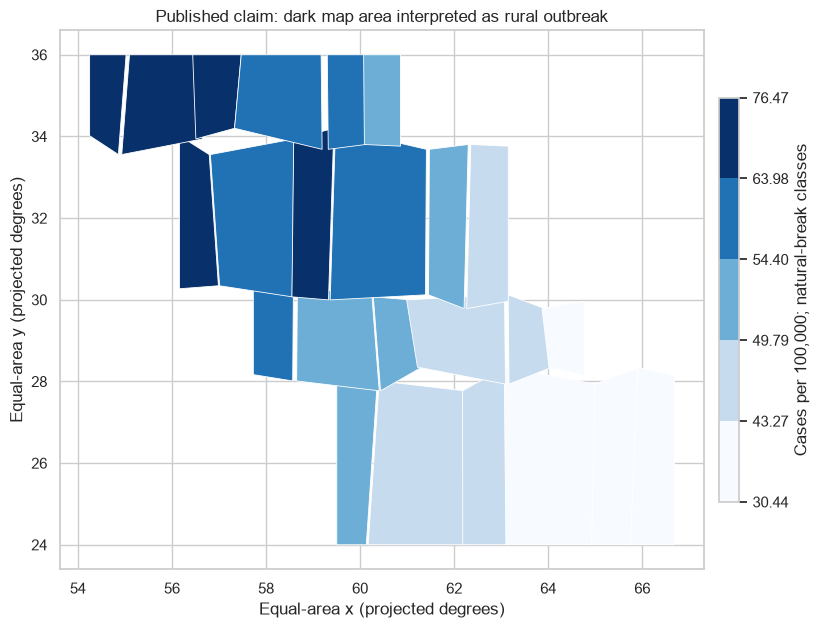

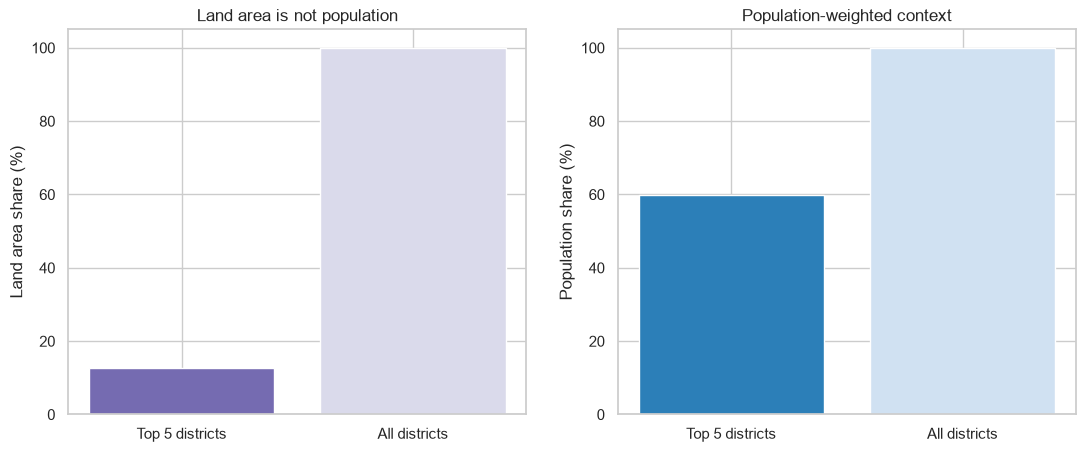

In [10]:
top5 = district.nlargest(5,'population')
print('Five most populous districts land share:', round(top5.area_km2.sum()/district.area_km2.sum()*100,1), '% | population share:', round(top5.population.sum()/district.population.sum()*100,1), '%')
raw_rate_breaks = natural_breaks(district.rate, 5)
classes = class_labels(district.rate, raw_rate_breaks)
print('Published top-two class count:', int(classes.astype(str).isin([str(x) for x in classes.cat.categories[-2:]]).sum()), 'districts')
draw_map(district.set_index('code').rate, 'Published claim: dark map area interpreted as rural outbreak', breaks=raw_rate_breaks, value_label='Cases per 100,000; natural-break classes'); plt.show()
fig, (ax1,ax2)=plt.subplots(1,2,figsize=(13,5));
ax1.bar(['Top 5 districts','All districts'], [top5.area_km2.sum()/district.area_km2.sum()*100,100], color=['#756bb1','#dadaeb']); ax1.set_ylabel('Land area share (%)'); ax1.set_title('Land area is not population')
ax2.bar(['Top 5 districts','All districts'], [top5.population.sum()/district.population.sum()*100,100], color=['#2c7fb8','#d0e1f2']); ax2.set_ylabel('Population share (%)'); ax2.set_title('Population-weighted context'); plt.show()


## 9. Region A encloses more radar area

**Invited conclusion:** Region A is stronger because its radar polygon encloses visibly more area.

**First objection and why it does not hold:** the two means are essentially tied, so the difference is not a broad level effect: the supplied means are 62.3 and 62.0.

**Mechanism:** radar polygon area depends on axis order, scaling, and the arbitrary choice to connect and fill six spokes. In the file order, the filled areas are 9,933 and 9,433 even though the means differ by only 0.33.


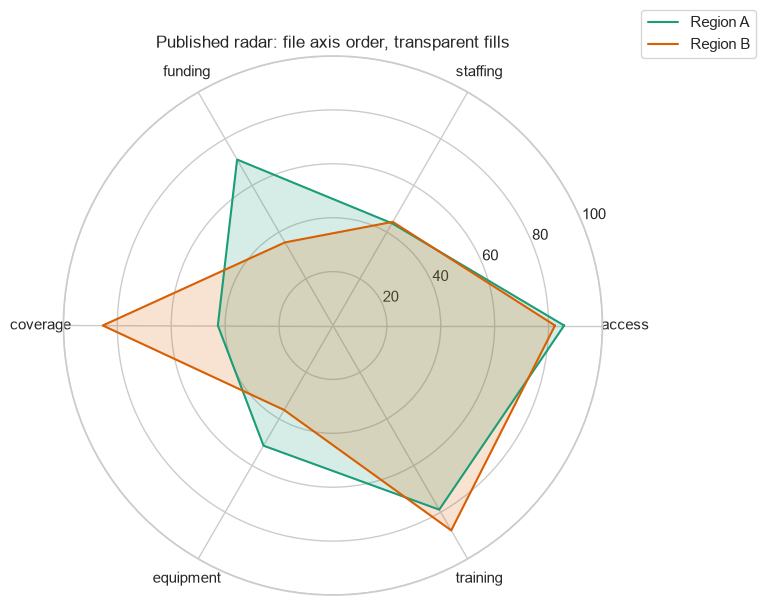

Means: 62.3 62.0 | difference: 0.33 | supplied polygon areas in file order: 9933 and 9433


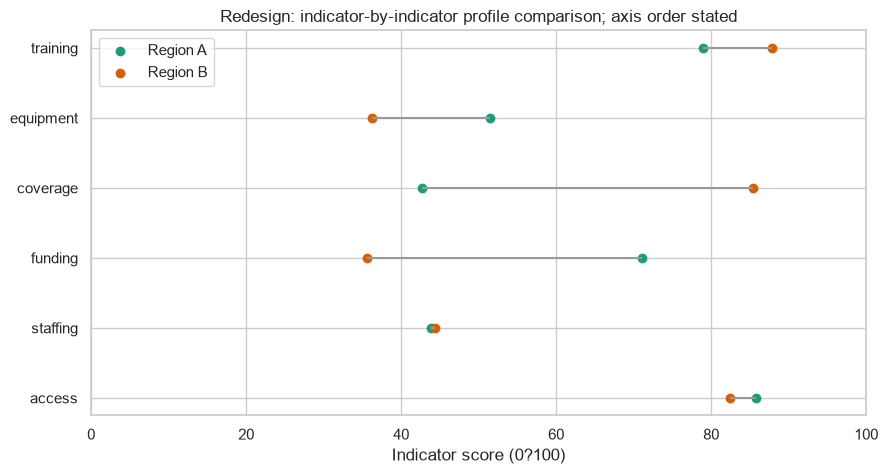

Radar polygon area is not used as an aggregate in the redesign because it changes with ordering and spoke geometry.


In [11]:
ind = profiles.indicator.tolist(); a=profiles.region_a.to_numpy(); b=profiles.region_b.to_numpy(); ang=np.linspace(0,2*np.pi,len(ind),endpoint=False); ang=np.r_[ang,ang[0]]
fig, ax=plt.subplots(figsize=(7,7),subplot_kw={'projection':'polar'}); ax.plot(ang,np.r_[a,a[0]],label='Region A',color='#1b9e77'); ax.fill(ang,np.r_[a,a[0]],alpha=.18,color='#1b9e77'); ax.plot(ang,np.r_[b,b[0]],label='Region B',color='#d95f02'); ax.fill(ang,np.r_[b,b[0]],alpha=.18,color='#d95f02'); ax.set_xticks(ang[:-1],ind); ax.set_ylim(0,100); ax.set_title('Published radar: file axis order, transparent fills'); ax.legend(loc='upper right',bbox_to_anchor=(1.3,1.1)); plt.show()
print('Means:', round(a.mean(),1), round(b.mean(),1), '| difference:', round(a.mean()-b.mean(),2), '| supplied polygon areas in file order: 9933 and 9433')
fig, ax=plt.subplots(figsize=(10,5)); y=np.arange(len(ind)); ax.hlines(y, b, a, color='#999999'); ax.scatter(a,y,color='#1b9e77',label='Region A'); ax.scatter(b,y,color='#d95f02',label='Region B'); ax.set_yticks(y,ind); ax.set_xlim(0,100); ax.set_xlabel('Indicator score (0?100)'); ax.set_title('Redesign: indicator-by-indicator profile comparison; axis order stated'); ax.legend(); plt.show()
print('Radar polygon area is not used as an aggregate in the redesign because it changes with ordering and spoke geometry.')


## Compact self-check summary

The notebook prints each required check alongside the corresponding chart. The key design corrections are: use area proportional to population (case 1), normalize counts by population (cases 2 and 8), state robust scaling and axis order (cases 3 and 4), avoid forced quantile contrast for near-equal rates (case 5), show uncertainty for small denominators (case 6), expose association and aggregation limits (case 7), and replace radar area with direct comparisons (case 9).
